In [ ]:
import numpy as np
import pandas as pd
import pulp
import matplotlib.pyplot as plt


In [2]:
rivers = ["River_A", "River_B"]
bronze_per_day = [0.3, 0.2]   
copper_per_day = [0.3, 0.4]   
bronze_needed = 2             
copper_needed = 3             


In [3]:
def solve_gold_canyon(rivers, bronze_per_day, copper_per_day, bronze_needed, copper_needed, cat="Continuous"):
    bronze_per_day = np.asarray(bronze_per_day, dtype=float)
    copper_per_day = np.asarray(copper_per_day, dtype=float)

    model = pulp.LpProblem("Gold_Canyon", pulp.LpMinimize)

    x = model.add_variable_dict("x", rivers, lowBound=0, cat=cat)

    model += pulp.lpSum(x[r] for r in rivers)

    # constraints
    model += pulp.lpSum(bronze_per_day[i] * x[r] for i, r in enumerate(rivers)) >= bronze_needed, "Bronze"
    model += pulp.lpSum(copper_per_day[i] * x[r] for i, r in enumerate(rivers)) >= copper_needed, "Copper"

    result = model.solve(pulp.HiGHS(msg=False))
    return model, x, result

In [4]:
model, x, result = solve_gold_canyon(rivers, bronze_per_day, copper_per_day, bronze_needed, copper_needed)
if result.status_str == "Optimal":
    print("Optimal plan:")
    for r in rivers:
        print(f"{r}: {x[r].value():.2f} days")
    print("Total days:", round(result.objective, 2))

Optimal plan:
River_A: 3.33 days
River_B: 5.00 days
Total days: 8.33


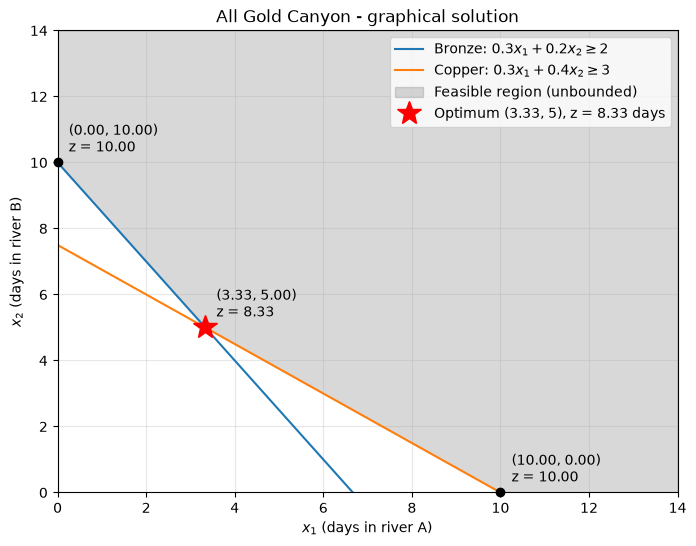

In [5]:
x1 = np.linspace(0, 14, 400)

# Each constraint written as x2 = ... (its boundary line)
bronze = (2 - 0.3 * x1) / 0.2     # 0.3*x1 + 0.2*x2 >= 2
copper = (3 - 0.3 * x1) / 0.4     # 0.3*x1 + 0.4*x2 >= 3

fig, ax = plt.subplots(figsize=(8, 6))

# 1. Constraint boundary lines
ax.plot(x1, bronze, label=r"Bronze: $0.3x_1 + 0.2x_2 \geq 2$")
ax.plot(x1, copper, label=r"Copper: $0.3x_1 + 0.4x_2 \geq 3$")

# 2. Feasible region: above both lines and x2 >= 0 (unbounded, shaded up to the top of the plot)
lower = np.maximum.reduce([bronze, copper, np.zeros_like(x1)])
ax.fill_between(x1, lower, 14, color="grey", alpha=0.3, label="Feasible region (unbounded)")

# 3. Corner points of the feasible region and the number of days at each
corners = [(0, 10), (10 / 3, 5), (10, 0)]
for cx, cy in corners:
    z = cx + cy
    ax.plot(cx, cy, "ko", clip_on=False)
    ax.annotate(f"({cx:.2f}, {cy:.2f})\nz = {z:.2f}", (cx, cy), textcoords="offset points", xytext=(8, 8))

# 4. Optimum
ax.plot(10 / 3, 5, "r*", markersize=18, clip_on=False, label="Optimum (3.33, 5), z = 8.33 days")

ax.set_xlim(0, 14)
ax.set_ylim(0, 14)
ax.set_xlabel("$x_1$ (days in river A)")
ax.set_ylabel("$x_2$ (days in river B)")
ax.set_title("All Gold Canyon - graphical solution")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.show()